# E1 · Справедливое распределение обязанностей

**Вопрос.** Как меняется доля дележей, удовлетворяющих EF1, когда одни и те же оценки означают сначала полезность благ, а затем затраты на обязанности?

Для каждого экземпляра берём одну матрицу на 3 участников и 6 неделимых позиций. В задаче о благах участник хочет получить больше пользы, а в задаче об обязанностях хочет понести меньше затрат. Каждый предмет или работа назначается ровно одному участнику. Пустые наборы разрешены.

Ноутбук выполняется сверху вниз. По умолчанию строятся данные, точный ориентир, эвристики и графики контрольного прогона. Тестовый запуск через Codex CLI включается в разделе 5.

**Среда.** Python 3.10+, NumPy, pandas, Matplotlib. Для Jupyter или Colab достаточно этих пакетов и Python-ядра.

## 1. Как генерируются входы

У Cookson, Ebadian и Shah (§2, *Synthetic data*) каждый экземпляр генерируется в три шага.

1. Один раз на весь экземпляр выбираем $p \sim \mathrm{Dirichlet}(1,\ldots,1)$, где $p_g$ — общая относительная значимость позиции $g$.
2. Для каждого участника независимо выбираем целый бюджет оценок $T_i$ равномерно от $(50-\lambda)m$ до $(50+\lambda)m$ включительно.
3. При фиксированных $p$ и $T_i$ распределяем $T_i$ баллов участника по позициям по закону $\mathrm{Multinomial}(T_i,p)$. В каждой строке получается ровно $T_i$ баллов. Из-за общего $p$ дорогие позиции обычно похожи для разных людей.

Статья использует этот генератор для благ, по умолчанию с $n=5$, $m=15$, $\lambda=20$ и 200 экземплярами на точку. Здесь воспроизводим закон генерации, а размер пилота берём из постановки E1. Те же исходные числа трактуем как затраты в парной задаче. В группе «Статья» сохраняем нули генератора. Нулевая стоимость означает бесплатную для участника работу.

[Cookson, Ebadian и Shah, *Fairness Perceptions of Large Language Models*, AAAI 2026, §2](https://ojs.aaai.org/index.php/AAAI/article/download/40848/44809)

| Группа | Исходные значения | Назначение |
|---|---|---|
| Статья | Общий $p$, строки из multinomial, $\lambda=20$ | Входы с общей структурой предпочтений |
| 1–10 | Независимые целые от 1 до 10 | Контроль из постановки E1 |
| $r=2,5,10$ | Независимый выбор 1 или $r$ с вероятностью $1/2$ | Меняем контраст между дешёвой и дорогой работой |

Для каждого базового номера один и тот же двоичный шаблон используется при всех $r$. Условия «Статья» и «1–10» получают свои случайные данные. После генерации каждую строку приводим к сумме 100 для оценки распределения. Модель видит исходные целые веса и точное правило пересчёта. Это сохраняет отношения внутри строки и убирает различия в суммах строк из задачи оптимизации. Поэтому в этом пилоте $\lambda$ фиксировано. Эффект разного бюджета строк, который изучали авторы статьи, здесь отдельно не оценивается.

In [1]:
import json
import os
import shutil
import subprocess
import time
from datetime import datetime, timezone
from itertools import product, zip_longest
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display

N_AGENTS = 3
N_ITEMS = 6
N_BASE = 20
SEED = 20261109
LAMBDA = 20
RATIOS = (2, 5, 10)
ROW_TOTAL = 100
ATOL = 1e-9
if any(type(r) is not int or r <= 1 for r in RATIOS):
    raise ValueError("Отношения r должны быть целыми и больше 1")
if tuple(sorted(set(RATIOS))) != RATIOS:
    raise ValueError("Укажите разные отношения r в возрастающем порядке")
GROUPS = ("paper", "uniform", *(f"r={r}" for r in RATIOS))
KINDS = ("goods", "chores")
GROUP_LABEL = {"paper": "Статья", "uniform": "1–10", **{f"r={r}": f"r={r}" for r in RATIOS}}
KIND_LABEL = {"goods": "Блага", "chores": "Обязанности"}

if min(N_AGENTS, N_ITEMS, N_BASE, ROW_TOTAL) <= 0:
    raise ValueError("Размеры задачи, число экземпляров и шкала должны быть положительными")
if not 0 <= LAMBDA < 50:
    raise ValueError("Для положительной суммы каждой строки нужно 0 ≤ LAMBDA < 50")

plt.rcParams.update({
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelcolor": "#233842",
    "text.color": "#18323b",
    "grid.color": "#dbe6e9",
    "axes.axisbelow": True,
})
TEAL, AMBER, SLATE = "#11786f", "#ab550e", "#506577"


def generate_paper(rng, n, m, lam):
    p = rng.dirichlet(np.ones(m))
    low, high = (50 - lam) * m, (50 + lam) * m
    totals = rng.integers(low, high + 1, size=n)
    weights = np.stack([rng.multinomial(total, p) for total in totals])
    return weights, p, totals


def build_instances():
    instances = {}
    for base_id in range(N_BASE):
        article_rng, uniform_rng, binary_rng = [
            np.random.default_rng(np.random.SeedSequence([SEED, base_id, stream]))
            for stream in range(3)
        ]
        paper, _, totals = generate_paper(article_rng, N_AGENTS, N_ITEMS, LAMBDA)
        assert np.array_equal(paper.sum(axis=1), totals)
        instances[base_id, "paper"] = paper
        instances[base_id, "uniform"] = uniform_rng.integers(1, 11, size=paper.shape)
        expensive = binary_rng.random(paper.shape) < 0.5
        for r in RATIOS:
            instances[base_id, f"r={r}"] = np.where(expensive, r, 1)
    return instances


def row_shares(weights):
    return weights / weights.sum(axis=1, keepdims=True)


instances = build_instances()
sample = instances[0, "paper"]
agents = [f"A{i + 1}" for i in range(N_AGENTS)]
items = [f"G{g + 1}" for g in range(N_ITEMS)]
example = pd.DataFrame(sample, index=agents, columns=items).assign(Сумма=sample.sum(axis=1))
display(example)

,G1,G2,G3,G4,G5,G6,Сумма
A1,10,71,133,52,29,110,405
A2,8,39,78,44,19,67,255
A3,10,62,116,63,13,97,361


На тепловой карте одна ячейка — доля баллов участника за одну позицию после приведения строки к 100. На гистограмме показаны суммы строк **до** нормировки. Второй график позволяет проверить, что при $\lambda=20$ бюджеты действительно различаются и лежат в диапазоне от 180 до 420 при $m=6$.

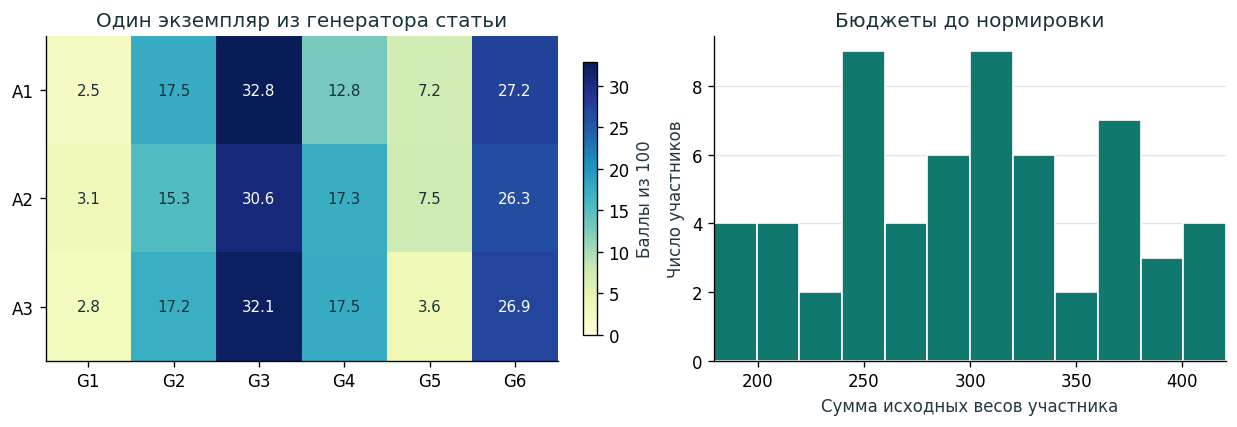

In [2]:
fig, (ax, hist) = plt.subplots(1, 2, figsize=(10.2, 3.45), layout="constrained")
normalized = ROW_TOTAL * row_shares(sample)
heat = ax.imshow(normalized, cmap="YlGnBu", aspect="auto", vmin=0)
ax.set(xticks=range(N_ITEMS), xticklabels=items, yticks=range(N_AGENTS),
       yticklabels=agents, title="Один экземпляр из генератора статьи")
for i, g in np.ndindex(normalized.shape):
    value = normalized[i, g]
    color = "white" if value > 0.62 * normalized.max() else "#18323b"
    ax.text(g, i, f"{value:.1f}", ha="center", va="center", color=color, fontsize=9)
fig.colorbar(heat, ax=ax, shrink=0.84, label=f"Баллы из {ROW_TOTAL}")

totals = np.concatenate([instances[i, "paper"].sum(axis=1) for i in range(N_BASE)])
low, high = (50 - LAMBDA) * N_ITEMS, (50 + LAMBDA) * N_ITEMS
bounds = (low - 0.5, high + 0.5)
hist.hist(totals, bins=np.linspace(*bounds, 13), color=TEAL, edgecolor="white")
hist.set(xlabel="Сумма исходных весов участника", ylabel="Число участников",
         title="Бюджеты до нормировки", xlim=bounds)
hist.grid(axis="y")
plt.show()

## 2. Как проверяется делёж

Пусть $X_i$ — набор участника $i$, а $w_i(S)$ — сумма нормированных оценок участника $i$ за набор $S$, выраженная в долях от 100. Для любой пары сначала считаем обычную зависть, потом вычитаем эффект одного наиболее ценного или затратного элемента.

| Задача | Зависть участника $i$ к $j$ до удаления | Откуда удаляем элемент для EF1 |
|---|---|---|
| Блага | $w_i(X_j)-w_i(X_i)$ | Из чужого набора $X_j$ |
| Обязанности | $w_i(X_i)-w_i(X_j)$ | Из собственного набора $X_i$ |

Если набор для удаления пуст, эффект удаления равен нулю. $E$ — максимальная положительная зависть до удаления. $d$ — максимальная положительная зависть после удаления. **EF1 выполнено, если $d=0$** с численным допуском $10^{-9}$.

Точный ориентир перебирает все $3^6=729$ назначений. Сначала минимизирует $d$. Среди распределений с минимальным $d$ максимизирует суммарную полезность для благ или минимизирует суммарные затраты для обязанностей.

Для диагностики у ответов на chores дополнительно проверяем два варианта. Если убрать самую дешёвую работу из чужого набора, сохранив знак сравнения для затрат, проверка становится строже обычного отсутствия зависти. Она не может принять делёж, который нарушает правильный EF1. Поэтому отдельно считаем более содержательный случай, когда тот же ответ прошёл бы **целую формулу для благ**, но провалил EF1 для обязанностей. По одному дележу нельзя установить, каким правилом пользовалась модель.

In [3]:
# Временный массив оценки всех наборов имеет размер A × n × n × m,
# где A = n ** m. Ограничиваем его, чтобы настройки пилота не исчерпали память.
if N_AGENTS ** N_ITEMS * N_AGENTS ** 2 * N_ITEMS > 10_000_000:
    raise ValueError("Задача слишком велика для точного перебора в этом ноутбуке")

ALL_OWNERS = np.array(list(product(range(N_AGENTS), repeat=N_ITEMS)), dtype=int)


def allocation_scores(weights, owners, kind):
    # owners[b, g] — получатель позиции g в распределении b.
    shares = row_shares(weights)
    n = len(weights)
    # assigned[b, j, g] показывает, лежит ли позиция g в наборе X_j.
    assigned = owners[:, None, :] == np.arange(n)[None, :, None]
    # bundle[b, i, j] — как i оценивает весь набор j.
    bundle = np.einsum("ig,bjg->bij", shares, assigned)
    own = bundle.diagonal(axis1=1, axis2=2)
    largest = np.max(shares[None, :, None, :] * assigned[:, None, :, :], axis=-1)
    largest_own = largest.diagonal(axis1=1, axis2=2)

    goods_envy = bundle - own[:, :, None]
    goods_residual = goods_envy - largest
    if kind == "goods":
        envy, residual = goods_envy, goods_residual
    else:
        envy = -goods_envy
        residual = envy - largest_own[:, :, None]

    # При ошибочном удалении из X_j сравнение легче всего выполнить,
    # убрав из чужого набора самую дешёвую для i работу.
    cheapest = np.min(
        np.where(assigned[:, None, :, :], shares[None, :, None, :], np.inf), axis=-1
    )
    cheapest = np.where(assigned.any(axis=-1)[:, None, :], cheapest, 0)

    return {
        "d": np.maximum(residual.max(axis=(1, 2)), 0),
        "envy": np.maximum(envy.max(axis=(1, 2)), 0),
        "total": ROW_TOTAL * own.sum(axis=1),
        # Для диагноза исключаем i=j: сравниваются только разные участники.
        "wrong_side_pass": np.max(
            np.where(np.eye(n, dtype=bool), 0, -goods_envy + cheapest), axis=(1, 2)
        ) <= ATOL,
        "goods_rule_pass": goods_residual.max(axis=(1, 2)) <= ATOL,
    }


def exact_reference(weights, kind):
    scores = allocation_scores(weights, ALL_OWNERS, kind)
    best_d = float(scores["d"].min())
    tied = np.flatnonzero(scores["d"] <= best_d + ATOL)
    total = scores["total"][tied]
    best = tied[np.argmax(total) if kind == "goods" else np.argmin(total)]
    return ALL_OWNERS[best], best_d, float(scores["total"][best])


def round_robin(weights):
    owners = np.full(weights.shape[1], -1, dtype=int)
    for turn in range(len(owners)):
        i = turn % len(weights)
        remaining = np.flatnonzero(owners < 0)
        owners[remaining[weights[i, remaining].argmax()]] = i
    return owners


def greedy_chores(weights):
    # Затраты аддитивны, поэтому прирост равен стоимости одной работы.
    # При равенстве выбираем участника с меньшим номером.
    return row_shares(weights).argmin(axis=0)

## 3. Промпт и проверка ответа

Промпты отличаются смыслом весов, стороной удаления и направлением оптимизации. Во всех остальных отношениях задания совпадают. Один прогон — один запрос с чистой историей. Проверяющий принимает один JSON с ключом `status` и списками работ или благ по участникам. Дубликат, пропуск, неизвестный ID или лишний текст делают ответ недопустимым.

In [4]:
def make_prompt(weights, kind):
    table = "\n".join(
        agent + " | " + " | ".join(map(str, row))
        for agent, row in zip(agents, weights)
    )
    if kind == "goods":
        task = "Распредели неделимые блага. Чем больше оценка набора, тем он лучше."
        residual = "max(0, оценка X_j после удаления одного блага − оценка X_i)"
        removal = "Удали из X_j самое ценное для i благо, если X_j непуст."
        objective = "максимизируй суммарную полезность полученных благ"
    else:
        task = "Распредели неделимые обязанности. Чем больше оценка набора, тем он обременительнее."
        residual = "max(0, оценка X_i после удаления одной работы − оценка X_j)"
        removal = "Удали из X_i самую затратную для i работу, если X_i непуст."
        objective = "минимизируй суммарные затраты на назначенные работы"

    schema_example = json.dumps({
        "status": "allocation",
        "bundles": {agent: ["ID", "..."] for agent in agents},
    }, ensure_ascii=False)
    return (
        f"{task}\n"
        "Назначь каждую позицию ровно одному участнику. Пустые наборы разрешены.\n"
        "В таблице исходные веса. Оценка набора S для участника i равна "
        f"{ROW_TOTAL} × (сумма весов позиций S в строке i) / (сумма всех весов в строке i).\n\n"
        f"Участник | {' | '.join(items)}\n{table}\n\n"
        "Обозначим через X_i набор участника i. Для каждой пары разных участников i и j "
        f"считай обе оценки от лица i. {removal} Остаток зависти равен {residual}. "
        "Если удалять нечего, используй исходный набор. Если все остатки равны нулю, "
        "делёж удовлетворяет EF1. Сначала минимизируй максимальный остаток зависти. "
        f"При равном остатке {objective}.\n\n"
        f"Верни один JSON без пояснений и без Markdown по схеме {schema_example}. "
        f"В списках используй только реальные ID от {items[0]} до {items[-1]}. "
        "Для пустого набора используй []."
    )


def unique_keys(pairs):
    result = dict(pairs)
    if len(result) != len(pairs):
        raise ValueError("Повтор ключа JSON")
    return result


def reject_json_constant(constant):
    raise ValueError(f"Недопустимое значение JSON: {constant}")


def parse_allocation(raw):
    if not isinstance(raw, str):
        raise ValueError("Пустой или нетекстовый ответ")
    try:
        answer = json.loads(raw, object_pairs_hook=unique_keys, parse_constant=reject_json_constant)
    except RecursionError as exc:
        raise ValueError("Слишком глубокая вложенность ответа JSON") from exc
    if not isinstance(answer, dict) or set(answer) != {"status", "bundles"}:
        raise ValueError("Ожидаются ровно status и bundles")
    if answer["status"] != "allocation":
        raise ValueError("Ожидается status=allocation")
    bundles = answer["bundles"]
    if not isinstance(bundles, dict) or set(bundles) != set(agents):
        raise ValueError("Неверный список участников")
    owners = np.full(N_ITEMS, -1, dtype=int)
    index = {item: g for g, item in enumerate(items)}
    for i, agent in enumerate(agents):
        if not isinstance(bundles[agent], list):
            raise ValueError("Набор участника должен быть списком")
        for item in bundles[agent]:
            if not isinstance(item, str) or item not in index:
                raise ValueError("Неизвестный ID позиции")
            g = index[item]
            if owners[g] != -1:
                raise ValueError("Позиция указана несколько раз")
            owners[g] = i
    if (owners == -1).any():
        raise ValueError("Некоторые позиции пропущены")
    return owners


def answer_metrics(weights, owners, kind, best_d, best_total):
    if owners is None:
        return {"valid": False, "ef1": False, "d": np.nan, "envy": np.nan,
                "total": np.nan, "gap": np.nan, "wrong_side_only": np.nan,
                "goods_rule_only": np.nan}
    scores = allocation_scores(weights, owners[None, :], kind)
    d = float(scores["d"][0])
    total = float(scores["total"][0])
    ef1 = d <= ATOL
    gap = best_total - total if kind == "goods" else total - best_total
    return {
        "valid": True,
        "ef1": ef1,
        "d": d,
        "envy": float(scores["envy"][0]),
        "total": total,
        "gap": max(0.0, gap) if d <= best_d + ATOL else np.nan,
        "wrong_side_only": bool(scores["wrong_side_pass"][0] and not ef1) if kind == "chores" else np.nan,
        "goods_rule_only": bool(scores["goods_rule_pass"][0] and not ef1) if kind == "chores" else np.nan,
    }


print(make_prompt(sample, "chores"))

Распредели неделимые обязанности. Чем больше оценка набора, тем он обременительнее.
Назначь каждую позицию ровно одному участнику. Пустые наборы разрешены.
В таблице исходные веса. Оценка набора S для участника i равна 100 × (сумма весов позиций S в строке i) / (сумма всех весов в строке i).

Участник | G1 | G2 | G3 | G4 | G5 | G6
A1 | 10 | 71 | 133 | 52 | 29 | 110
A2 | 8 | 39 | 78 | 44 | 19 | 67
A3 | 10 | 62 | 116 | 63 | 13 | 97

Обозначим через X_i набор участника i. Для каждой пары разных участников i и j считай обе оценки от лица i. Удали из X_i самую затратную для i работу, если X_i непуст. Остаток зависти равен max(0, оценка X_i после удаления одной работы − оценка X_j). Если удалять нечего, используй исходный набор. Если все остатки равны нулю, делёж удовлетворяет EF1. Сначала минимизируй максимальный остаток зависти. При равном остатке минимизируй суммарные затраты на назначенные работы.

Верни один JSON без пояснений и без Markdown по схеме {"status": "allocation", "bundles": 

## 4. Контрольный прогон

Для каждого входа сравниваем точный перебор с простым алгоритмом. Для благ участники по очереди выбирают самое ценное оставшееся благо. Для обязанностей каждую работу отдаём тому, для кого она дешевле по нормированной шкале. Жадный алгоритм минимизирует общие аддитивные затраты и может нарушить EF1.

Перед прогоном проверяем граничное равенство, зависть к пустому набору, разницу двух формул EF1 и разбор JSON.

In [5]:
trial = np.array([[6, 4, 3], [2, 7, 3]])
owners = np.array([[0, 0, 1]])
assert np.isclose(allocation_scores(trial, owners, "chores")["d"][0], 1 / 13)
assert allocation_scores(trial, owners, "goods")["d"][0] == 0
trial[0, 1] = 3
assert allocation_scores(trial, owners, "chores")["d"][0] <= ATOL
assert allocation_scores(trial, np.array([[0, 0, 0]]), "chores")["d"][0] > 0

wrong_side_trial = np.array([[1, 1, 1, 5], [1, 5, 1, 1]])
split = np.array([[0, 0, 1, 1]])
assert allocation_scores(wrong_side_trial, split, "chores")["wrong_side_pass"][0]

valid_json = {"status": "allocation", "bundles": {agent: [] for agent in agents}}
valid_json["bundles"][agents[0]] = items
assert np.array_equal(parse_allocation(json.dumps(valid_json)), np.zeros(N_ITEMS, dtype=int))
invalid_json = {
    "status": "allocation",
    "bundles": {**valid_json["bundles"], agents[0]: [*items, items[0]]},
}
try:
    parse_allocation(json.dumps(invalid_json))
except ValueError:
    pass
else:
    raise AssertionError("Разборщик пропустил дубликаты")

references = {}
baseline_rows = []
for (base_id, group), weights in instances.items():
    for kind in KINDS:
        best, best_d, best_total = exact_reference(weights, kind)
        references[base_id, group, kind] = best_d, best_total
        heuristic = round_robin(weights) if kind == "goods" else greedy_chores(weights)
        for method, assigned in (("Точный перебор", best), ("Эвристика", heuristic)):
            baseline_rows.append({
                "base_id": base_id, "group": group, "kind": kind, "method": method,
                **answer_metrics(weights, assigned, kind, best_d, best_total),
            })

print(f"Проверки пройдены. Экземпляров: {len(instances)}. Контрольных решений: {len(baseline_rows)}.")

Проверки пройдены. Экземпляров: 100. Контрольных решений: 400.


## 5. Тестовый запуск через Codex

Установите Codex CLI в той же среде, где запущено ядро Jupyter. Если ядро работает в WSL, команды запускайте в WSL. Выполните `codex login`, войдите через ChatGPT и проверьте вход командой `codex login status`. Отдельный ключ OpenAI API для ноутбука не нужен.

1. Поставьте `RUN_CODEX = True` и выполните ячейку, затем раздел с результатами.
2. Настройки по умолчанию дают два запроса. Codex получает одну матрицу из группы «Статья» отдельно как задачу о благах и как задачу об обязанностях.
3. Чтобы расширить тест, измените `CODEX_BASES` и `CODEX_REPEATS`. Для всех групп укажите `CODEX_GROUPS = GROUPS`. Чтобы зафиксировать модель, задайте её ID в `CODEX_MODEL`.

Каждый запрос запускается в отдельной сессии Codex с пустой рабочей папкой и выключенными инструментами оболочки, веб-поиска, приложений и подагентов. Код сохраняет вход, промпт, исходный ответ, время и токены из журнала CLI, если они доступны. Некорректный JSON считается ответом с ошибкой формата. Ответ попадает в расчёт после события завершения запроса. Ошибка CLI останавливает запуск и остаётся в журнале.

Чтобы повторно посчитать метрики по завершённому прогону, оставьте `RUN_CODEX = False` и укажите путь к его JSONL-файлу в `REPLAY_LOG`. Входы, промпты и порядок запросов сверяются с журналом.

[Вход в Codex CLI через ChatGPT](https://learn.chatgpt.com/docs/auth) · [Запуск через codex exec](https://learn.chatgpt.com/docs/non-interactive-mode)

In [6]:
RUN_CODEX = False
REPLAY_LOG = None
CODEX_BASES = 1
CODEX_GROUPS = ("paper",)  # Для всех групп установите CODEX_GROUPS = GROUPS.
CODEX_REPEATS = 1
CODEX_MODEL = None  # None использует модель Codex CLI по умолчанию.
CODEX_TIMEOUT = 180  # Секунд на один запрос.


def trial_keys(base_count, groups, repeats):
    if type(base_count) is not int or not 1 <= base_count <= N_BASE:
        raise ValueError(f"Число экземпляров Codex должно быть целым от 1 до {N_BASE}")
    if type(repeats) is not int or repeats < 1:
        raise ValueError("Число повторов Codex должно быть положительным целым")
    if not isinstance(groups, (list, tuple)) or not groups:
        raise ValueError("Укажите непустой список или кортеж групп из GROUPS")
    if any(not isinstance(g, str) or g not in GROUPS for g in groups) or len(set(groups)) != len(groups):
        raise ValueError("Укажите непустой набор разных групп из GROUPS")
    return list(product(range(base_count), groups, range(1, repeats + 1), KINDS))


def read_json_object(text, context):
    try:
        data = json.loads(text, object_pairs_hook=unique_keys, parse_constant=reject_json_constant)
    except (ValueError, RecursionError) as exc:
        raise ValueError(f"{context}: некорректный JSON") from exc
    if not isinstance(data, dict):
        raise ValueError(f"{context}: ожидался объект JSON")
    return data


def run_codex_turn(executable, env, workspace, prompt):
    output_path = Path(workspace) / "reply.txt"
    output_path.unlink(missing_ok=True)
    command = [
        executable, "--ask-for-approval", "never", "exec", "--sandbox", "read-only",
        "--ignore-user-config", "--ignore-rules", "--skip-git-repo-check", "--ephemeral",
        "--disable", "shell_tool", "--disable", "apps", "--disable", "multi_agent",
        "-c", 'web_search="disabled"', "-c", "project_doc_max_bytes=0",
        "-c", f"log_dir={json.dumps(env['CODEX_SQLITE_HOME'], ensure_ascii=False)}",
        "--json", "--output-last-message", str(output_path),
    ]
    if CODEX_MODEL is not None:
        command.extend(("--model", CODEX_MODEL))
    result = subprocess.run(
        [*command, "-"], input=prompt, cwd=workspace, env=env, capture_output=True,
        encoding="utf-8", errors="replace", timeout=CODEX_TIMEOUT,
    )
    if result.returncode != 0:
        details = "\n".join(result.stderr.strip().splitlines()[-4:])
        raise RuntimeError(f"Codex CLI завершился с кодом {result.returncode}. {details}".strip())
    if not output_path.is_file():
        raise RuntimeError("Codex CLI не записал финальный ответ")

    completed = None
    for line_number, line in enumerate(result.stdout.split("\n"), 1):
        if not line.strip():
            continue
        event = read_json_object(line, f"Событие Codex, строка {line_number}")
        if event.get("type") == "turn.failed":
            raise RuntimeError("Codex CLI сообщил о неудачном запросе (turn.failed)")
        if event.get("type") == "turn.completed":
            if completed is not None:
                raise RuntimeError("Codex CLI сообщил о завершении больше одного запроса")
            completed = event
    if completed is None:
        raise RuntimeError("Codex CLI не подтвердил завершение запроса (turn.completed)")
    usage = completed.get("usage")
    if usage is not None:
        if not isinstance(usage, dict):
            raise ValueError("Codex CLI вернул некорректную статистику токенов")
        json.dumps(usage, allow_nan=False)  # Проверяем, что статистику можно записать в журнал.
    return output_path.read_text(encoding="utf-8"), usage


def write_codex_record(journal, record):
    journal.write(json.dumps(record, ensure_ascii=False, allow_nan=False) + "\n")
    journal.flush()


def run_codex():
    plan = trial_keys(CODEX_BASES, CODEX_GROUPS, CODEX_REPEATS)
    executable = shutil.which("codex")
    if executable is None:
        raise RuntimeError("Codex CLI не найден в PATH ядра Jupyter")
    if CODEX_TIMEOUT <= 0:
        raise ValueError("Укажите положительный таймаут Codex")

    env = os.environ.copy()
    for key in ("OPENAI_API_KEY", "CODEX_API_KEY"):
        env.pop(key, None)
    with (
        TemporaryDirectory(prefix="chores-e1-work-") as workspace,
        TemporaryDirectory(prefix="chores-e1-state-") as state,
    ):
        env["CODEX_SQLITE_HOME"] = state
        status = subprocess.run(
            [executable, "login", "status"], cwd=workspace, env=env, capture_output=True,
            encoding="utf-8", errors="replace", timeout=30,
        )
        if status.returncode != 0 or "chatgpt" not in (status.stdout + status.stderr).lower():
            raise RuntimeError("Выполните codex login и войдите через ChatGPT")
        version = subprocess.run(
            [executable, "--version"], cwd=workspace, env=env, capture_output=True,
            encoding="utf-8", errors="replace", timeout=30, check=True,
        ).stdout.strip()
        stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
        path = Path(f"chores_e1_codex_{stamp}.jsonl")
        print(f"Запросов к Codex: {len(plan)}. Журнал: {path.resolve()}", flush=True)

        with path.open("x", encoding="utf-8") as journal:
            write_codex_record(journal, {
                "type": "config", "schema": 1, "seed": SEED, "row_total": ROW_TOTAL,
                "base_count": CODEX_BASES, "groups": list(CODEX_GROUPS), "repeats": CODEX_REPEATS,
                "model": CODEX_MODEL, "cli_version": version, "timeout": CODEX_TIMEOUT,
            })
            for base_id, group, repeat, kind in plan:
                weights = instances[base_id, group]
                prompt = make_prompt(weights, kind)
                started = time.perf_counter()
                raw = usage = error = None
                try:
                    raw, usage = run_codex_turn(executable, env, workspace, prompt)
                except subprocess.TimeoutExpired:
                    error = f"Таймаут Codex после {CODEX_TIMEOUT} с"
                except (RuntimeError, OSError, ValueError, KeyError, TypeError) as exc:
                    error = str(exc)
                write_codex_record(journal, {
                    "type": "reply", "base_id": base_id, "group": group, "repeat": repeat, "kind": kind,
                    "weights": weights.tolist(), "prompt": prompt, "raw_answer": raw,
                    "usage": usage, "seconds": time.perf_counter() - started, "cli_error": error,
                })
                if error is not None:
                    raise RuntimeError(f"{error}\nЗаписанная часть прогона: {path.resolve()}")
    return path


def score_codex_log(path):
    with Path(path).open(encoding="utf-8") as journal:
        config = read_json_object(journal.readline(), "Строка 1 журнала")
        if config.get("type") != "config" or config.get("schema") != 1:
            raise ValueError("Строка 1 журнала: ожидаются настройки прогона Codex E1")
        if config.get("seed") != SEED or config.get("row_total") != ROW_TOTAL:
            raise ValueError("Настройки генератора или шкалы отличаются от журнала")
        try:
            plan = trial_keys(config.get("base_count"), config.get("groups"), config.get("repeats"))
        except ValueError as exc:
            raise ValueError(f"Строка 1 журнала: {exc}") from exc
        groups = tuple(config["groups"])
        rows = []
        for line_number, (key, line) in enumerate(zip_longest(plan, journal), 2):
            if key is None or line is None:
                raise ValueError("Журнал содержит лишние ответы или прогон прерван")
            record = read_json_object(line, f"Строка {line_number} журнала")
            base_id, group, repeat, kind = key
            weights = instances[base_id, group]
            recorded_key = tuple(record.get(field) for field in ("base_id", "group", "repeat", "kind"))
            if record.get("type") != "reply" or recorded_key != key:
                raise ValueError(f"Строка {line_number}: ответ не соответствует плану")
            if record.get("cli_error") is not None:
                raise ValueError(f"Строка {line_number}: прогон прерван ошибкой Codex CLI")
            if record.get("weights") != weights.tolist() or record.get("prompt") != make_prompt(weights, kind):
                raise ValueError(f"Строка {line_number}: вход или промпт отличаются от журнала")
            raw, seconds, usage = (record.get(name) for name in ("raw_answer", "seconds", "usage"))
            if not isinstance(raw, str) or type(seconds) not in (int, float) or not 0 <= seconds < float("inf"):
                raise ValueError(f"Строка {line_number}: ответ или время выполнения записаны некорректно")
            if usage is not None and not isinstance(usage, dict):
                raise ValueError(f"Строка {line_number}: некорректная статистика токенов")

            assignment = format_error = None
            try:
                assignment = parse_allocation(raw)
            except ValueError as exc:
                format_error = str(exc)
            best_d, best_total = references[base_id, group, kind]
            rows.append({
                "base_id": base_id, "group": group, "kind": kind, "method": "Codex",
                "repeat": repeat, "seconds": seconds, "usage": usage,
                "format_error": format_error,
                **answer_metrics(weights, assignment, kind, best_d, best_total),
            })
    return rows, groups, config["base_count"]


codex_rows = []
active_groups, active_bases = GROUPS, N_BASE
if RUN_CODEX and REPLAY_LOG is not None:
    raise ValueError("Выберите новый запуск или чтение готового журнала")
if RUN_CODEX:
    log_path = run_codex()
elif REPLAY_LOG is not None:
    log_path = Path(REPLAY_LOG)
else:
    log_path = None

if log_path is not None:
    codex_rows, active_groups, active_bases = score_codex_log(log_path)
    print(f"Проверено ответов Codex: {len(codex_rows)}.")
else:
    print("Codex выключен. На графиках контрольные алгоритмы.")

Codex выключен. На графиках контрольные алгоритмы.


## 6. Результаты и графики

**Доля EF1** — число допустимых ответов с EF1, делённое на число всех ответов. Ошибка формата уменьшает эту долю. Зависть $E$, остаток $d$ и суммарная оценка считаются только на допустимых ответах. Разрыв с точным ориентиром считаем только для распределений, достигших минимального $d$.

Для каждого показателя сначала усредняем повторы одного экземпляра. Затем усредняем экземпляры, для которых показатель определён. 95%-е интервалы строятся бутстрэпом по базовым номерам. При пересэмплировании сохраняем вместе все условия одного номера. На втором графике разность «обязанности минус блага» вычисляется внутри пары. У линии эвристики разность включает также различие самих алгоритмов. При одном экземпляре показываем точку без интервала. При наличии ответов Codex сравниваем все методы только на тех экземплярах и группах, которые получил Codex.

,,,Допустимость,Доля EF1,d,Зависть E,Сумма SW/C,Разрыв с ориентиром,Только чужое удаление,Только правило благ
method,kind,group,,,,,,,,
Точный перебор,goods,paper,1.0,1.00,0.000,0.205,109.611,0.000,NaN,NaN
Эвристика,goods,paper,1.0,1.00,0.000,0.268,102.118,7.493,NaN,NaN
Точный перебор,chores,paper,1.0,1.00,0.000,0.226,90.664,0.000,0.0,0.0
Эвристика,chores,paper,1.0,0.35,0.113,0.380,90.094,0.000,0.0,0.0
Точный перебор,goods,uniform,1.0,1.00,0.000,0.119,141.930,0.000,NaN,NaN
Эвристика,goods,uniform,1.0,1.00,0.000,0.054,131.789,10.141,NaN,NaN
Точный перебор,chores,uniform,1.0,1.00,0.000,0.075,59.699,0.000,0.0,0.0
Эвристика,chores,uniform,1.0,0.75,0.016,0.125,58.941,0.000,0.0,0.0
Точный перебор,goods,r=2,1.0,1.00,0.000,0.107,126.012,0.000,NaN,NaN


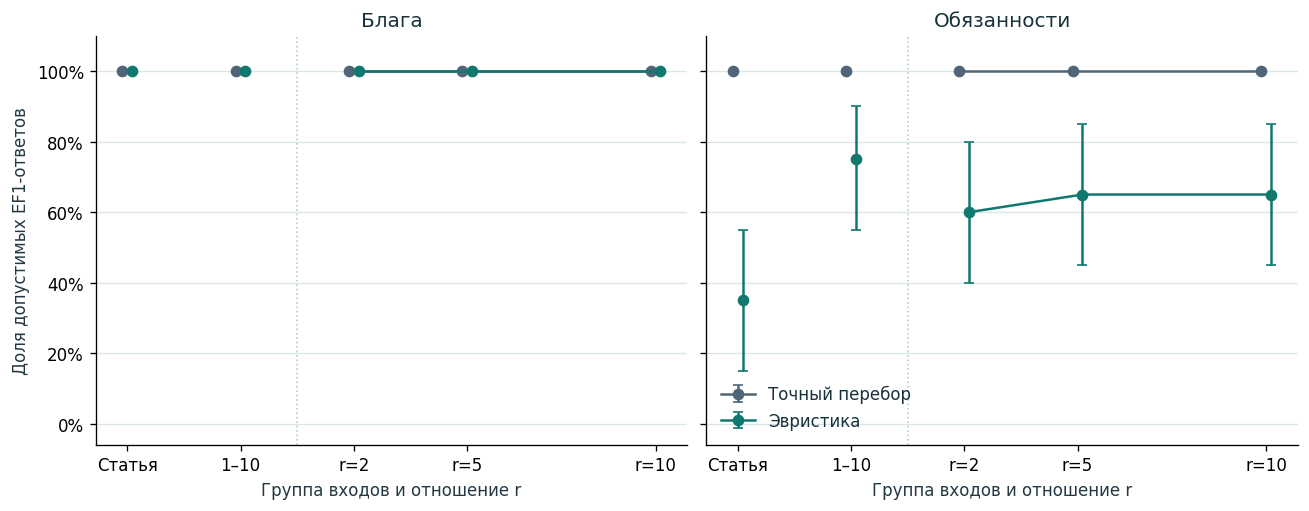

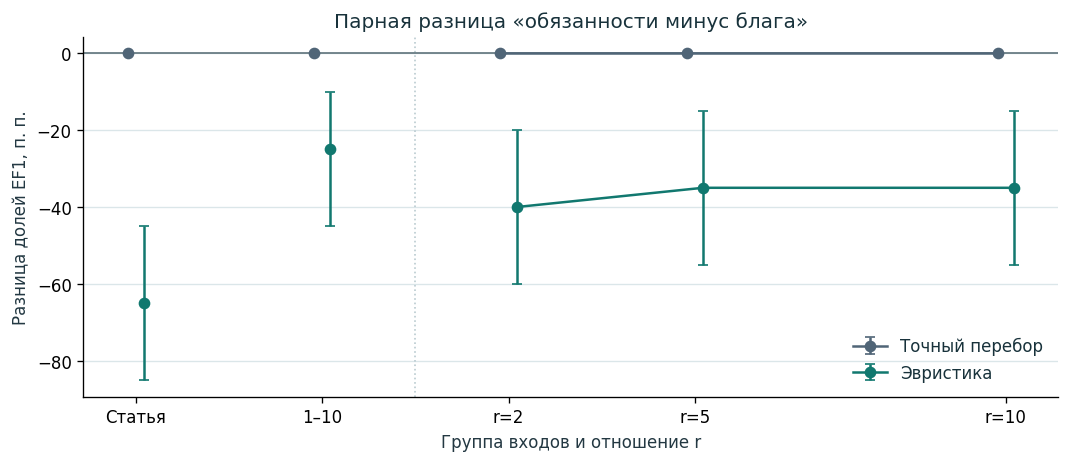

In [7]:
baseline = pd.DataFrame(baseline_rows)
baseline = baseline[
    (baseline["base_id"] < active_bases) & baseline["group"].isin(active_groups)
]
results = pd.concat([baseline, pd.DataFrame(codex_rows)], ignore_index=True) if codex_rows else baseline
metrics = ["valid", "ef1", "d", "envy", "total", "gap", "wrong_side_only", "goods_rule_only"]
results[metrics] = results[metrics].astype(float)
by_base = results.groupby(["method", "kind", "group", "base_id"], sort=False)[metrics].mean()
summary = by_base.groupby(level=["method", "kind", "group"], sort=False)[metrics].mean()
display(summary.rename(columns={
    "valid": "Допустимость", "ef1": "Доля EF1", "envy": "Зависть E",
    "total": "Сумма SW/C", "gap": "Разрыв с ориентиром",
    "wrong_side_only": "Только чужое удаление", "goods_rule_only": "Только правило благ",
}).round(3))

rng = np.random.default_rng(SEED + 1)
resamples = rng.integers(active_bases, size=(3000, active_bases))
group_x = dict(zip(GROUPS, [-4, -1, *RATIOS]))
controls = [group for group in GROUPS[:2] if group in active_groups]
ratios = [group for group in GROUPS[2:] if group in active_groups]


def estimate(series):
    values = series.reindex(range(active_bases)).to_numpy()
    low, high = np.quantile(values[resamples].mean(axis=1), [0.025, 0.975])
    return values.mean(), low, high


def draw_groups(ax, values, offset, label, color):
    for subset, style in ((controls, "o"), (ratios, "o-")):
        if not subset:
            continue
        mean, low, high = np.array([
            estimate(values.xs(group, level="group")) for group in subset
        ]).T
        x = np.array([group_x[group] for group in subset]) + offset
        errors = None if active_bases < 2 else np.maximum([mean - low, high - mean], 0)
        ax.errorbar(x, mean, yerr=errors, color=color, fmt=style, capsize=3,
                    label=label if subset == ratios or not ratios else None)


def style_groups(ax):
    ax.set_xticks([group_x[group] for group in active_groups],
                  [GROUP_LABEL[group] for group in active_groups])
    if controls and ratios:
        ax.axvline(0.5, color="#bacbd0", linestyle=":", linewidth=1)
    ax.set_xlabel("Группа входов и отношение r" if ratios else "Группа входов")
    ax.grid(axis="y")
    ax.yaxis.set_major_formatter(PercentFormatter(1))


methods = list(results["method"].unique())
colors = [SLATE, TEAL, AMBER]
offsets = np.linspace(-0.13, 0.13, len(methods))
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.15), sharey=True, layout="constrained")
for ax, kind in zip(axes, KINDS):
    for method, offset, color in zip(methods, offsets, colors):
        values = by_base["ef1"].xs((method, kind), level=("method", "kind"))
        draw_groups(ax, values, offset, method, color)
    style_groups(ax)
    ax.set(title=KIND_LABEL[kind], ylim=(-0.06, 1.1))
axes[0].set_ylabel("Доля допустимых EF1-ответов")
axes[1].legend(loc="lower left", frameon=False)
plt.show()

fig, ax = plt.subplots(figsize=(8.8, 3.75), layout="constrained")
for method, offset, color in zip(methods, offsets, colors):
    paired = by_base["ef1"].xs(method, level="method").unstack("kind")
    draw_groups(ax, paired["chores"] - paired["goods"], offset, method, color)
style_groups(ax)
ax.axhline(0, color="#5f737b", linewidth=1)
if active_bases == 1:
    ax.set_ylim(-1.05, 1.05)
ax.set(title="Парная разница «обязанности минус блага»", ylabel="Разница долей EF1, п. п.")
ax.yaxis.set_major_formatter(PercentFormatter(1, symbol=""))
ax.legend(frameon=False)
plt.show()

### Как читать контрольный прогон

При сохранённых настройках точный перебор нашёл EF1 во всех 20 экземплярах группы «Статья». Для обязанностей жадное назначение прошло проверку в 7 из 20 случаев (35%). Это результаты выбранных входов и контрольных алгоритмов.

- Точный перебор показывает, достижимо ли EF1 на каждом экземпляре. Его результат служит ориентиром и для сравнения суммарной полезности или затрат.
- Если жадное назначение не достигает EF1, его низкие суммарные затраты сами по себе не делают делёж справедливым.
- Точки «Статья» и «1–10» — отдельные условия. Линия соединяет только группы $r=2,5,10$, где у одного базового номера меняется цена дорогой позиции при фиксированном шаблоне.
- Сохранённые графики показывают офлайн-контроль. После запуска Codex к графикам добавятся его результаты на выбранных входах.